In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/pet-breed-classifier'
for d in ['src', 'notebooks', 'models', 'reports/figures', 'data']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)

%cd {PROJECT}

import torch
print(torch.__version__, '| GPU:', torch.cuda.is_available())

Mounted at /content/drive
/content/drive/MyDrive/pet-breed-classifier
2.11.0+cu130 | GPU: True


In [ ]:
%%writefile src/data.py
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# ImageNet-ის სტატისტიკა: pretrained მოდელები ამ ნორმალიზაციით ვარჯიშობდნენ
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

Writing src/data.py


In [ ]:
%%writefile -a src/data.py


def get_transforms(train: bool, augment: bool = True, size: int = 224):
    """train=True და augment=True: შემთხვევითი ცვლილებები.
    სხვა შემთხვევაში: დეტერმინისტული resize + normalize."""
    if train and augment:
        return transforms.Compose([
            transforms.RandomResizedCrop(size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    return transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

Appending to src/data.py


In [ ]:
%%writefile -a src/data.py


def get_dataloaders(root="data", batch_size=32, val_frac=0.2,
                    augment=True, size=224, seed=42, num_workers=2):
    # ერთი და იგივე სურათები, ოღონდ სხვადასხვა transform-ით
    train_ds = datasets.OxfordIIITPet(
        root, split="trainval", target_types="category",
        transform=get_transforms(True, augment, size), download=True)
    val_ds = datasets.OxfordIIITPet(
        root, split="trainval", target_types="category",
        transform=get_transforms(False, size=size), download=True)
    test_ds = datasets.OxfordIIITPet(
        root, split="test", target_types="category",
        transform=get_transforms(False, size=size), download=True)

    # trainval-ის გაყოფა train/val-ად ფიქსირებული seed-ით
    n = len(train_ds)
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g).tolist()
    n_val = int(n * val_frac)
    val_idx, train_idx = perm[:n_val], perm[n_val:]

    train_set = Subset(train_ds, train_idx)
    val_set = Subset(val_ds, val_idx)

    kw = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=True)
    train_loader = DataLoader(train_set, shuffle=True, **kw)
    val_loader = DataLoader(val_set, shuffle=False, **kw)
    test_loader = DataLoader(test_ds, shuffle=False, **kw)

    return train_loader, val_loader, test_loader, train_ds.classes

Appending to src/data.py


In [ ]:
from src.data import get_dataloaders

train_loader, val_loader, test_loader, classes = get_dataloaders(root='data')

x, y = next(iter(train_loader))
print('batch:', x.shape, y.shape)
print('კლასები:', len(classes), classes[:3])
print('train/val/test:', len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
print('pixel min/max:', x.min().item(), x.max().item())

100%|██████████| 792M/792M [00:32<00:00, 24.7MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.3MB/s]


batch: torch.Size([32, 3, 224, 224]) torch.Size([32])
კლასები: 37 ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier']
train/val/test: 2944 736 3669
pixel min/max: -2.1179039478302 2.640000104904175


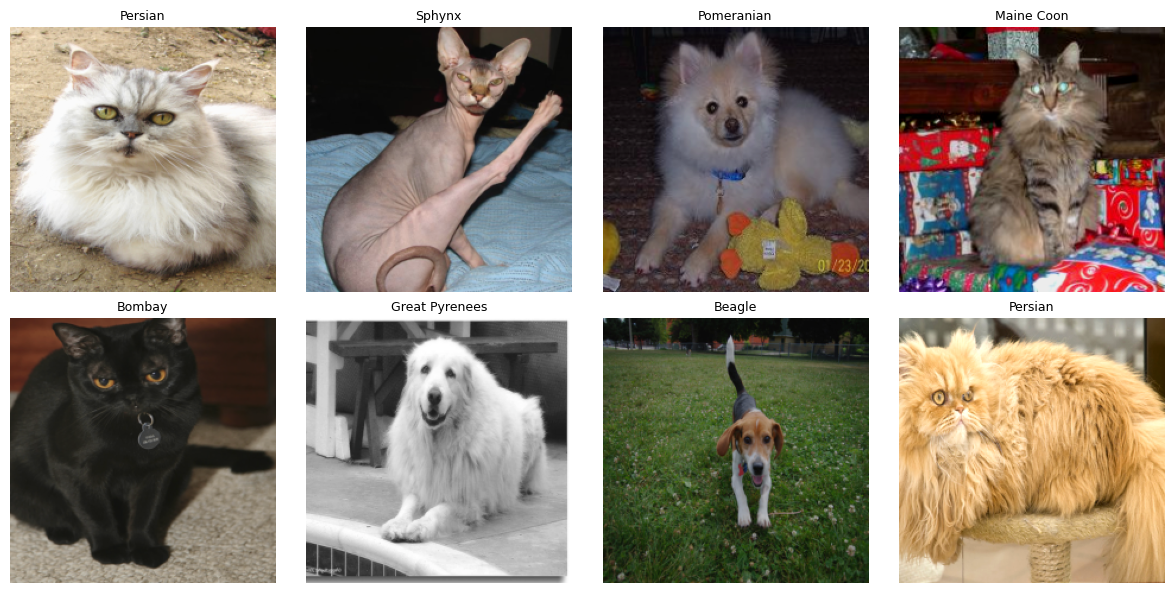

In [ ]:
import matplotlib.pyplot as plt
import torch
from src.data import MEAN, STD

def denormalize(img):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (img * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, label in zip(axes.flat, x[:8], y[:8]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(classes[label], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

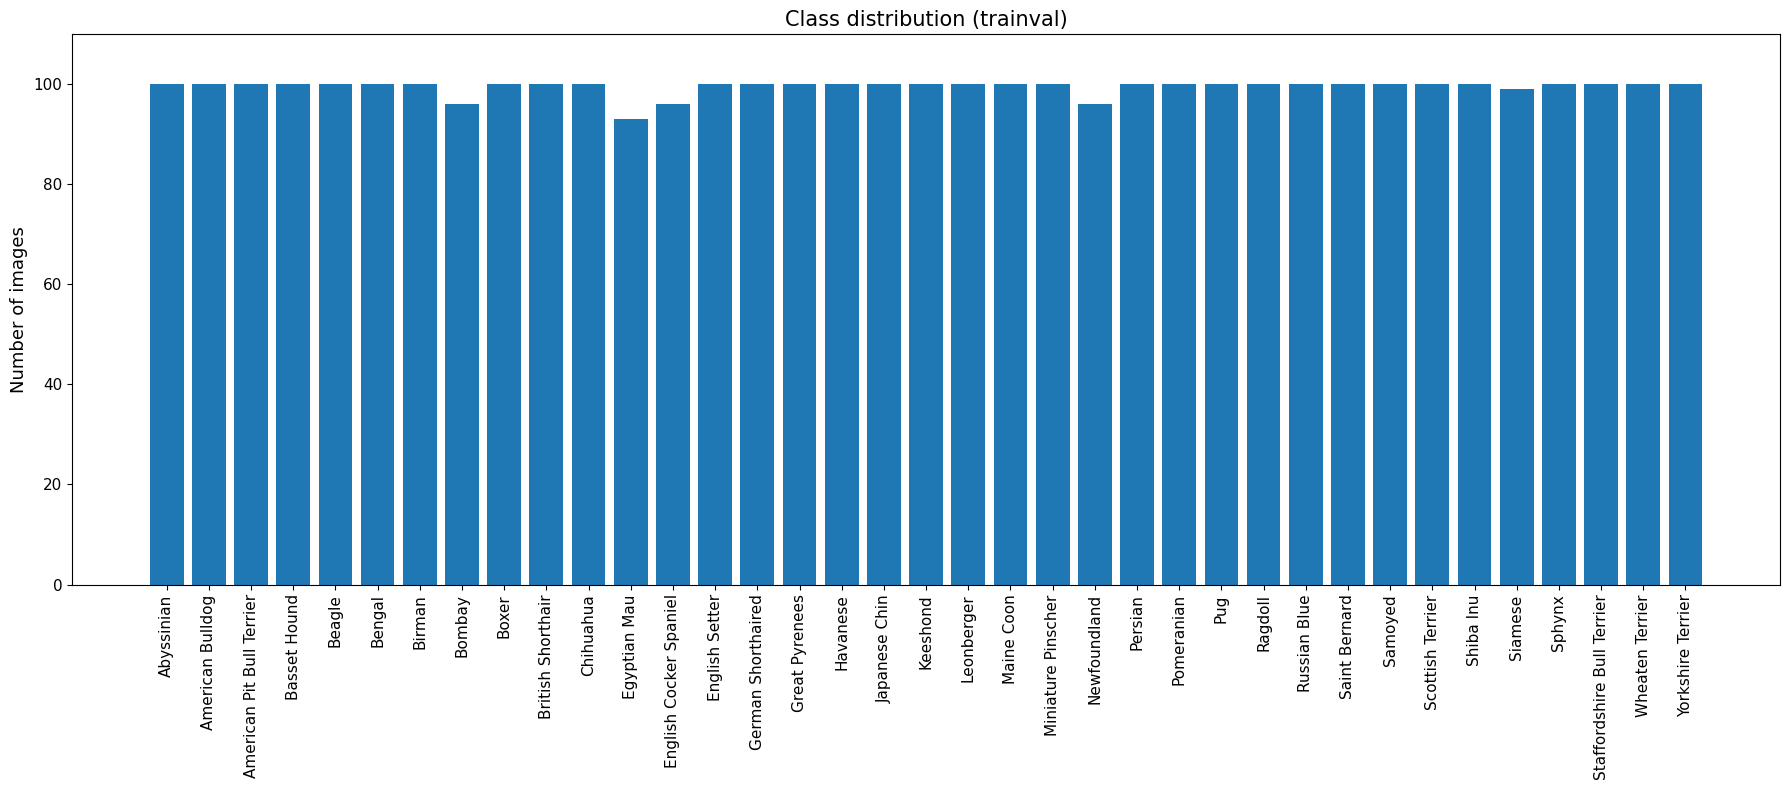

min: 93 | max: 100 | mean: 99.45945945945945


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

all_labels = train_loader.dataset.dataset._labels
counts = Counter(all_labels)

names = [classes[i] for i in sorted(counts)]
values = [counts[i] for i in sorted(counts)]

plt.figure(figsize=(18, 8))
plt.bar(names, values)
plt.xticks(rotation=90, fontsize=11)
plt.yticks(fontsize=11)
plt.ylabel('Number of images', fontsize=13)
plt.title('Class distribution (trainval)', fontsize=15)
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

print('min:', min(values), '| max:', max(values), '| mean:', sum(values) / len(values))